<a href="https://colab.research.google.com/github/AaronYounger/Quantitative-Finance/blob/main/Portfolio%20GARCH%20Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.0 MB/s  0:00:00


In [2]:
import pandas as pd
import numpy as np
import math
from arch import arch_model
import yfinance as yf
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy.stats import norm
from scipy import stats
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tsa.stattools import kpss
from scipy.stats import t as student_t, chi2

In [3]:
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

Import Assets for Portolio:

- AAPL
- MSFT
- TSLA
- AVGO
- JPM

In [4]:
aapl = yf.download(
    tickers="AAPL",
    start="2021-01-01",
    end="2026-11-11",
    interval="1d",
    auto_adjust=True
)
aapl = aapl.stack(level="Ticker", future_stack=False).reset_index()

[*********************100%***********************]  1 of 1 completed


In [5]:
aapl['aapl_ret'] = aapl['Close'].pct_change()
aapl = aapl.dropna()

In [6]:
msft = yf.download(
    tickers="MSFT",
    start="2021-01-01",
    end="2026-11-11",
    interval="1d",
    auto_adjust=True
)
msft = msft.stack(level="Ticker", future_stack=False).reset_index()
msft['msft_ret'] = msft['Close'].pct_change()
msft = msft.dropna()

tsla = yf.download(
    tickers="TSLA",
    start="2021-01-01",
    end="2026-11-11",
    interval="1d",
    auto_adjust=True
)
tsla = tsla.stack(level="Ticker", future_stack=False).reset_index()
tsla['tsla_ret'] = tsla['Close'].pct_change()
tsla = tsla.dropna()

avgo = yf.download(
    tickers="AVGO",
    start="2021-01-01",
    end="2026-11-11",
    interval="1d",
    auto_adjust=True
)
avgo = avgo.stack(level="Ticker", future_stack=False).reset_index()
avgo['avgo_ret'] = avgo['Close'].pct_change()
avgo = avgo.dropna()

jpm = yf.download(
    tickers="JPM",
    start="2021-01-01",
    end="2026-11-11",
    interval="1d",
    auto_adjust=True
)
jpm = jpm.stack(level="Ticker", future_stack=False).reset_index()
jpm['jpm_ret'] = jpm['Close'].pct_change()
jpm = jpm.dropna()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [7]:
aapl = aapl[['Date', 'aapl_ret']]

In [8]:
msft = msft[['Date', 'msft_ret']]
tsla = tsla[['Date', 'tsla_ret']]
avgo = avgo[['Date', 'avgo_ret']]
jpm = jpm[['Date', 'jpm_ret']]

Combine Assets into a single Dataframe

In [9]:
asset_df = pd.merge(
    aapl,
    msft,
    on="Date",
    how="inner"
)

In [10]:
asset_df = pd.merge(
    asset_df,
    tsla,
    on="Date",
    how="inner"
)

In [11]:
asset_df = pd.merge(
    asset_df,
    avgo,
    on="Date",
    how="inner"
)

In [12]:
asset_df = pd.merge(
    asset_df,
    jpm,
    on="Date",
    how="inner"
)

In [13]:
asset_df

Price,Date,aapl_ret,msft_ret,tsla_ret,avgo_ret,jpm_ret
0,2021-01-05,0.012364,0.000965,0.007317,0.006773,0.005441
1,2021-01-06,-0.033661,-0.025929,0.028390,-0.006167,0.046956
2,2021-01-07,0.034123,0.028457,0.079447,0.042143,0.032839
3,2021-01-08,0.008631,0.006093,0.078403,0.005074,0.001104
4,2021-01-11,-0.023249,-0.009699,-0.078214,0.000269,0.014924
...,...,...,...,...,...,...
1465,2026-11-04,0.053058,0.066815,-0.033400,-0.020022,0.041807
1466,2026-11-05,-0.015279,-0.035750,-0.107739,-0.104308,-0.041947
1467,2026-11-06,-0.005230,-0.009927,0.042276,0.007409,-0.008448
1468,2026-11-09,0.024301,0.027459,0.055357,0.087814,0.022691


Make Portfolio Returns with equally weighted portfolio

In [14]:
weights = np.array([0.2, 0.2, 0.2, 0.2, 0.2])
asset_df['port_ret'] = asset_df[['aapl_ret', 'msft_ret', 'tsla_ret', 'avgo_ret', 'jpm_ret']] @ weights

In [15]:
port_df = asset_df[['Date', 'port_ret']]

In [16]:
port_df

Price,Date,port_ret
0,2021-01-05,0.006572
1,2021-01-06,0.001918
2,2021-01-07,0.043402
3,2021-01-08,0.019861
4,2021-01-11,-0.019194
...,...,...
1465,2026-11-04,0.021652
1466,2026-11-05,-0.061004
1467,2026-11-06,0.005216
1468,2026-11-09,0.043524


Finalize Dataset for GARCH Modeling

In [17]:
port_df['log_ret'] = np.log1p(port_df['port_ret'])

/tmp/ipykernel_6381/2086159586.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  port_df['log_ret'] = np.log1p(port_df['port_ret'])


In [18]:
port_df['log_ret_100'] = port_df['log_ret'] * 100

/tmp/ipykernel_6381/212063588.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  port_df['log_ret_100'] = port_df['log_ret'] * 100


In [19]:
port_df = port_df.set_index("Date")

In [20]:
port_df

Price,port_ret,log_ret,log_ret_100
Date,,,
2021-01-05,0.006572,0.006550,0.655045
2021-01-06,0.001918,0.001916,0.191593
2021-01-07,0.043402,0.042486,4.248625
2021-01-08,0.019861,0.019667,1.966650
2021-01-11,-0.019194,-0.019380,-1.938030
...,...,...,...
2026-11-04,0.021652,0.021421,2.142052
2026-11-05,-0.061004,-0.062945,-6.294458
2026-11-06,0.005216,0.005203,0.520254


Data Checks Before GARCH

- Check for Stationarity
- ARCH effect
- Visual Analysis

(Applications of GARCH Models in Forecasting Financial Market Volatility: Insights from Leading Global Stock Indexes) SSRN

In [21]:
## Dataframe that will be used for GARCH Modeling
r = port_df['log_ret_100']

In [22]:
## Check for Stationarity
adf_test = adfuller(r)
kpss_test = kpss(r, regression='c', nlags='auto')

print(f"ADF Statistic: {adf_test[0]}")
print(f"ADF P-value: {adf_test[1]:.5f}")
print(f"KPSS Statistic: {kpss_test[0]}")
print(f"KPSS P-value: {kpss_test[1]:.5f}")

ADF Statistic: -23.394360902861145
ADF P-value: 0.00000
KPSS Statistic: 0.06560479551911012
KPSS P-value: 0.10000


Data is Stationary

In [25]:
## Is a GARCH Model Needed
resid = r - r.mean()
arch_test = het_arch(resid, nlags=10)
print(f"Arch-test statistic: {arch_test[0]}")
print(f"Arch-test pvalues: {arch_test[1]}")

Arch-test statistic: 95.10569403104441
Arch-test pvalues: 5.174202775000471e-16


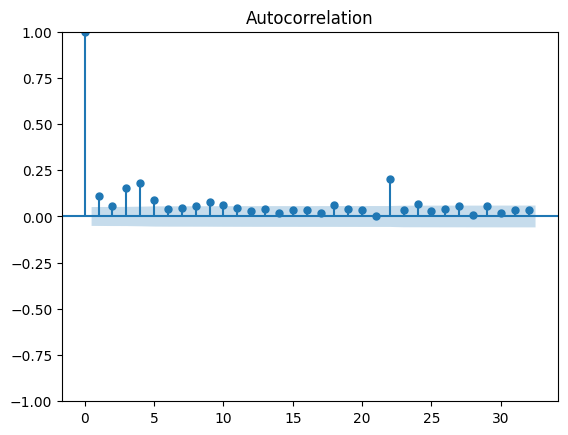

In [26]:
squared_resid = resid ** 2

plot_acf(squared_resid, alpha=0.05)
plt.show()

GARCH Model is justified

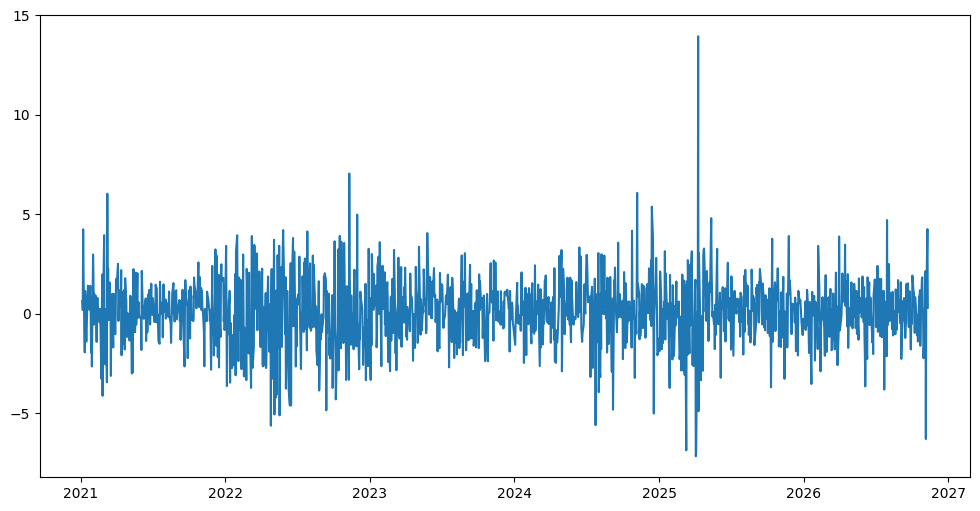

In [27]:
## Exihibits Volatility Clustering
plt.figure(figsize=(12,6))
plt.plot(r)
plt.show()

GARCH does not try and predict the direction of returns but rather predicts the size of the next movve, using this idea of volatility clustering.

Fit GARCH Model

**Note:** We will be using GJR-GARCH to capture the assymetry of volatility, "Bad news hits harder than Good news".

In [28]:
gjr_garch = arch_model(r, mean = "constant", vol='GARCH', p=1, o=1, q=1, dist='t')
gjr_res = gjr_garch.fit(disp="off")
print(gjr_res.summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                  log_ret_100   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -2701.10
Distribution:      Standardized Student's t   AIC:                           5414.21
Method:                  Maximum Likelihood   BIC:                           5445.97
                                              No. Observations:                 1470
Date:                      Thu, Nov 12 2026   Df Residuals:                     1469
Time:                              23:23:39   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [29]:
## Extract Parameters from Model
mu = gjr_res.params['mu'] ## Average Daily Return of the portfolio
omega = gjr_res.params['omega'] ## Constant baseline in the variance equation
alpha = gjr_res.params['alpha[1]'] ## The effect of yesterday's positive shock on today's variance (Insignficant)
gamma = gjr_res.params['gamma[1]'] ## The extra effect of a negative shockk on today's variance on top of alpha
beta = gjr_res.params['beta[1]'] ## How much of yesterday's variance carries over into today's
nu = gjr_res.params['nu'] ## A value above 30 equates to gaussian distribution, this value being < 30 justifies a student t distribution
std_resid = gjr_res.std_resid
conditional_vol = gjr_res.conditional_volatility

Goodness of Fit | Did the GARCH Model Work?

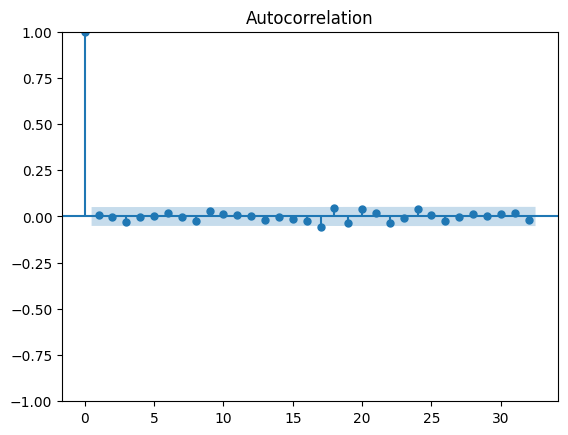

,lb_stat,lb_pvalue
10,4.620992,0.915018
20,18.531882,0.552414


In [30]:
## Check if direction of returns still have some predictability
plot_acf(std_resid, alpha=0.05)
plt.show()
mean_ljungbox_test = acorr_ljungbox(std_resid, lags=[10, 20], return_df=True)
mean_ljungbox_test


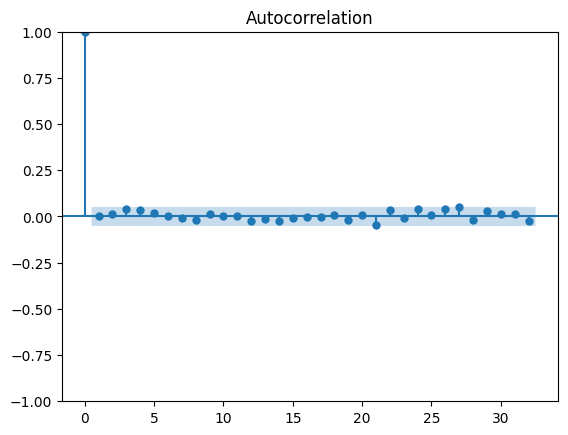

,lb_stat,lb_pvalue
10,5.991226,0.816000
20,8.834830,0.984743


In [31]:
plot_acf(std_resid ** 2, alpha=0.05)
plt.show()
var_ljungbox_test = acorr_ljungbox(std_resid ** 2, lags=[10, 20], return_df=True)
var_ljungbox_test

Decision Making Metrics

In [32]:
persistance = alpha + beta + (0.5*gamma)
print(f"Persistance of volatility is: {persistance:.4f}")

Persistance of volatility is: 0.9754


In [33]:
# Half Life
half_life = math.log(0.5) / math.log(persistance)
print(f"Half life: {half_life:.2f}")

Half life: 27.81


In [34]:
unconditional_var = omega / (1 - persistance)
unconditional_vol = np.sqrt(unconditional_var)
ann_unconditional_vol = unconditional_vol * np.sqrt(252)

print(f"Daily Unconditional Volatility {unconditional_vol:.2f}%")
print(f"Annualized Unconditional Volatility {ann_unconditional_vol:.2f}%")

Daily Unconditional Volatility 1.61%
Annualized Unconditional Volatility 25.49%


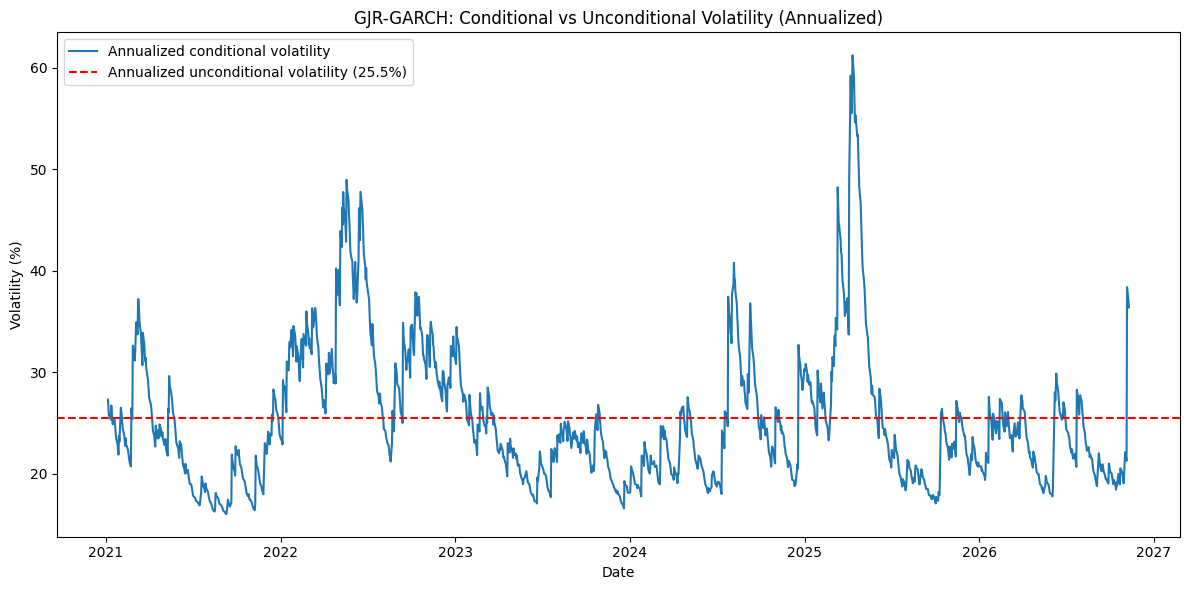

In [35]:
ann_conditional_vol = conditional_vol * np.sqrt(252)

plt.figure(figsize=(12, 6))
plt.plot(ann_conditional_vol, label='Annualized conditional volatility')
plt.axhline(ann_unconditional_vol, color='r', linestyle='--',
            label=f'Annualized unconditional volatility ({ann_unconditional_vol:.1f}%)')
plt.title('GJR-GARCH: Conditional vs Unconditional Volatility (Annualized)')
plt.xlabel('Date')
plt.ylabel('Volatility (%)')
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
print(ann_conditional_vol.tail(6))
print(r.tail(6))

Date
2026-11-03    22.044303
2026-11-04    21.520360
2026-11-05    21.285131
2026-11-06    38.383114
2026-11-09    37.033925
2026-11-10    36.385416
Name: cond_vol, dtype: float64
Date
2026-11-03    0.365124
2026-11-04    2.142052
2026-11-05   -6.294458
2026-11-06    0.520254
2026-11-09    4.260386
2026-11-10    0.307705
Name: log_ret_100, dtype: float64


In [37]:
## Where we have been
ratio = ann_conditional_vol / ann_unconditional_vol
ratio.tail(6)

,cond_vol
Date,
2026-11-03,0.864957
2026-11-04,0.844399
2026-11-05,0.835169
2026-11-06,1.506046
2026-11-09,1.453108
2026-11-10,1.427662


In [38]:
## where we are today
one_day_var = gjr_res.forecast(horizon=1).variance.iloc[-1]
one_day_forecast = np.sqrt(one_day_var * 252)

## Today Ratio
today_ratio = one_day_forecast / ann_unconditional_vol

print(f"Today's Annual Conditional Volatility {one_day_forecast}")
print(f"Today's Ratio {today_ratio}")

Today's Annual Conditional Volatility h.1    35.125293
Name: 2026-11-10 00:00:00, dtype: float64
Today's Ratio h.1    1.378218
Name: 2026-11-10 00:00:00, dtype: float64


In [39]:
## Five Day Forecast

five_day_forecast = gjr_res.forecast(horizon=5).variance.iloc[-1]
five_day_forecast = np.sqrt(five_day_forecast * 252)
five_day_forecast = five_day_forecast[-1]

five_day_ratio = five_day_forecast / ann_unconditional_vol

print(f"Five day Annual Conditional Volatility {five_day_forecast}")
print(f"Five day Ratio {five_day_ratio}")

Five day Annual Conditional Volatility 34.32707302524866
Five day Ratio 1.34689835081706


In [40]:
## One Month Forecast

one_month_forecast = gjr_res.forecast(horizon=21).variance.iloc[-1]
one_month_forecast = np.sqrt(one_month_forecast * 252)
one_month_forecast = one_month_forecast[-1]

one_month_ratio = one_month_forecast / ann_unconditional_vol

print(f"Five day Annual Conditional Volatility {one_month_forecast}")
print(f"Five day Ratio {one_month_ratio}")

Five day Annual Conditional Volatility 31.69290104142771
Five day Ratio 1.243540808559749


In [41]:
## Effects of Assymetric Drops
### Drop of 5%
move = -5
var_drop = omega + (alpha + gamma) * (move)**2 + beta * one_day_var
var_up = omega + alpha * (-move)**2 + beta * one_day_var

vol_drop = np.sqrt(var_drop * 252)
vol_up = np.sqrt(var_up * 252)

print(f"Conditional Volatility now {one_day_forecast}")
print(f"Conditional Volatility after a 5% drop {vol_drop}")
print(f"Conditional Volatility after a 5% increase {vol_up}")

Conditional Volatility now h.1    35.125293
Name: 2026-11-10 00:00:00, dtype: float64
Conditional Volatility after a 5% drop h.1    42.235329
Name: 2026-11-10 00:00:00, dtype: float64
Conditional Volatility after a 5% increase h.1    34.905138
Name: 2026-11-10 00:00:00, dtype: float64


In [42]:
## VaR and ES estimate
a   = 0.05
t_a = student_t.ppf(a, nu)                     # regular t quantile
s   = np.sqrt((nu - 2) / nu)                   # standardization factor

q05       = t_a * s
es_factor = s * (student_t.pdf(t_a, nu) / a) * (nu + t_a**2) / (nu - 1)

# Whole sample
garch_var = -(mu + conditional_vol * q05)
garch_es  = -mu + conditional_vol * es_factor
hist_var  = -r.rolling(252).quantile(0.05).shift(1)

# Tomorrow
var_one_day_var = gjr_res.forecast(horizon=1).variance.iloc[-1, 0]
one_day_sigma   = np.sqrt(var_one_day_var)

# Historical, last 252 days
last_252 = r.iloc[-252:]
hist_var_now = -last_252.quantile(0.05)
hist_es_now  = -last_252[last_252 <= -hist_var_now].mean()

print(f"Tomorrow's 95% GARCH VaR:  {-(mu + one_day_sigma * q05):.2f}%")
print(f"Tomorrow's 95% GARCH ES:   {-mu + one_day_sigma * es_factor:.2f}%")
print(f"Latest 95% historical VaR: {hist_var_now:.2f}%")
print(f"Latest 95% historical ES:  {hist_es_now:.2f}%")



Tomorrow's 95% GARCH VaR:  3.44%
Tomorrow's 95% GARCH ES:   4.71%
Latest 95% historical VaR: 2.10%
Latest 95% historical ES:  3.03%


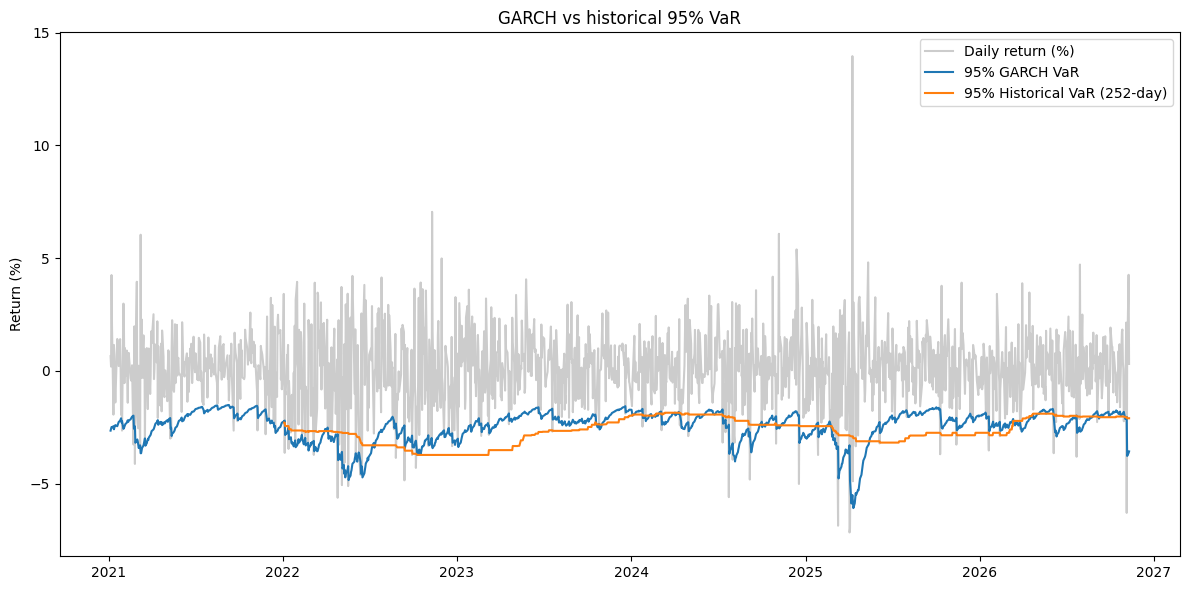

In [43]:
plt.figure(figsize=(12, 6))
plt.plot(r, color='grey', alpha=0.4, label='Daily return (%)')
plt.plot(-garch_var, label='95% GARCH VaR')
plt.plot(-hist_var,  label='95% Historical VaR (252-day)')
plt.title('GARCH vs historical 95% VaR')
plt.ylabel('Return (%)'); plt.legend(); plt.tight_layout(); plt.show()

In [46]:
from scipy.stats import chi2
from scipy.special import xlogy

def kupiec(breaches, p=0.05):
    n, x = len(breaches), breaches.sum()
    ph = x / n
    LR = -2 * (xlogy(n - x, 1 - p) + xlogy(x, p)
               - xlogy(n - x, 1 - ph) - xlogy(x, ph))
    return ph, x, LR, chi2.sf(LR, 1)

def christoffersen(breaches):
    b = breaches.astype(int).values
    prev, curr = b[:-1], b[1:]
    n00 = ((prev == 0) & (curr == 0)).sum()
    n01 = ((prev == 0) & (curr == 1)).sum()
    n10 = ((prev == 1) & (curr == 0)).sum()
    n11 = ((prev == 1) & (curr == 1)).sum()

    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)

    ll_null = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll_alt  = (xlogy(n00, 1 - pi01) + xlogy(n01, pi01)
               + xlogy(n10, 1 - pi11) + xlogy(n11, pi11))
    LR = -2 * (ll_null - ll_alt)
    return n11, LR, chi2.sf(LR, 1)

In [47]:
## Kupiec & Christoffersen

common = hist_var.dropna().index          # historical VaR starts after 252 days, so compare on the same dates

breaches_garch = r.loc[common] < -garch_var.loc[common]
breaches_hist  = r.loc[common] < -hist_var.loc[common]

# ---------- Run both tests on each model ----------
rows = []
for name, b in [('GARCH', breaches_garch), ('Historical 252-day', breaches_hist)]:
    rate, x, LR_pof, p_pof = kupiec(b)
    n11, LR_ind, p_ind     = christoffersen(b)
    p_cc = chi2.sf(LR_pof + LR_ind, 2)               # combined (conditional coverage)
    rows.append({
        'Model': name,
        'Days': len(b),
        'Breaches': x,
        'Rate': f"{rate:.1%}",
        'Kupiec p': round(p_pof, 3),
        'Back-to-back': n11,
        'Christoffersen p': round(p_ind, 3),
        'Combined p': round(p_cc, 3),
        'Breaches Mar–May 2025': b.loc['2025-03-01':'2025-05-31'].sum(),
    })

pd.DataFrame(rows).set_index('Model')


,Days,Breaches,Rate,Kupiec p,Back-to-back,Christoffersen p,Combined p,Breaches Mar–May 2025
Model,,,,,,,,
GARCH,1218,73,6.0%,0.122,4,0.845,0.298,3
Historical 252-day,1218,68,5.6%,0.359,6,0.266,0.354,7
